In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Q1
# Change to the name of the TSV file you downloaded from NOAA
EQ_FILE = r"C:\Users\Lenovo\Downloads\earthquakes-2026-10-14_20-30-46_+0800.tsv"

Sig_Eqs = pd.read_csv(EQ_FILE, sep="\t")
Sig_Eqs.columns = [c.strip() for c in Sig_Eqs.columns]
print(Sig_Eqs.columns.tolist())

['Search Parameters', 'Id', 'Year', 'Mo', 'Dy', 'Hr', 'Mn', 'Sec', 'Tsu', 'Vol', 'Country', 'Area', 'Region', 'Location Name', 'Latitude', 'Longitude', 'Focal Depth (km)', 'Mag', 'Mw', 'Ms', 'Mb', 'Ml', 'Mfa', 'Unk', 'MMI Int', 'Deaths', 'Death Description', 'Missing', 'Missing Description', 'Injuries', 'Injuries Description', 'Damage ($Mil)', 'Damage Description', 'Houses Destroyed', 'Houses Destroyed Description', 'Houses Damaged', 'Houses Damaged Description', 'Total Deaths', 'Total Death Description', 'Total Missing', 'Total Missing Description', 'Total Injuries', 'Total Injuries Description', 'Total Damage ($Mil)', 'Total Damage Description', 'Total Houses Destroyed', 'Total Houses Destroyed Description', 'Total Houses Damaged', 'Total Houses Damaged Description']


In [3]:
# Country: use the 'Country' column if it exists, otherwise parse "COUNTRY: region" from 'Location Name'
if "Country" not in Sig_Eqs.columns:
    Sig_Eqs["Country"] = Sig_Eqs["Location Name"].astype(str).str.split(":").str[0].str.strip()
Sig_Eqs["Country"] = Sig_Eqs["Country"].astype(str).str.strip().str.upper()

# Magnitude column: the assignment says Ms; fall back to 'Mag' if it is not present
MAG = "Ms" if "Ms" in Sig_Eqs.columns else "Mag"
print("Magnitude column used:", MAG)

Magnitude column used: Ms


In [4]:
# 1.1 Total deaths per country, top 20 
deaths = (Sig_Eqs.groupby("Country")["Deaths"].sum(min_count=1)
          .dropna().sort_values(ascending=False))
print(deaths.head(20).astype(int).to_string())

Country
CHINA           2139209
TURKEY          1199720
IRAN            1014453
ITALY            492236
SYRIA            419826
HAITI            323484
AZERBAIJAN       319251
JAPAN            242516
ARMENIA          177890
PAKISTAN         145085
IRAQ             136200
ECUADOR          135496
TURKMENISTAN     117412
PERU             102309
ISRAEL            93388
PORTUGAL          83572
GREECE            81162
CHILE             64277
INDIA             63507
TAIWAN            57154


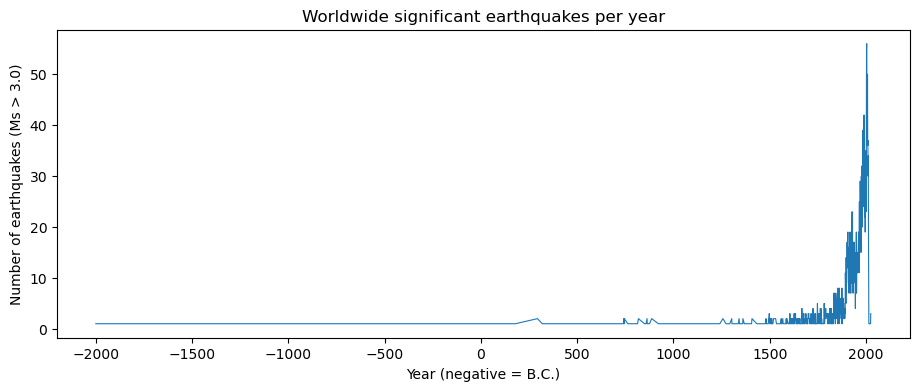

Trend since 1900: 0.169 events/yr, p = 3.54e-10


In [5]:
# 1.2 Yearly number of earthquakes with Ms > 3.0 
big = Sig_Eqs[Sig_Eqs[MAG] > 3.0]
yearly = big.groupby("Year").size()          # negative years = B.C.

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(yearly.index, yearly.values, lw=0.8)
ax.set_xlabel("Year (negative = B.C.)")
ax.set_ylabel(f"Number of earthquakes ({MAG} > 3.0)")
ax.set_title("Worldwide significant earthquakes per year")
plt.show()

# Trend check since 1900
y = yearly[yearly.index >= 1900]
res = stats.linregress(y.index, y.values)
print(f"Trend since 1900: {res.slope:.3f} events/yr, p = {res.pvalue:.2e}")

In [6]:
#1.3 CountEq_LargestEq
def CountEq_LargestEq(country, df=Sig_Eqs, mag_col=MAG):
    """Return (number of earthquakes, date of largest quake, location of largest quake)."""
    sub = df[df["Country"] == country.upper()]
    n = len(sub)
    sub_m = sub.dropna(subset=[mag_col])
    if sub_m.empty:
        return n, None, None
    row = sub_m.loc[sub_m[mag_col].idxmax()]

    def g(c):
        v = row.get(c, np.nan)
        return int(v) if pd.notna(v) else None

    date = f"{g('Year')}-{g('Mo')}-{g('Dy')}"
    return n, date, row.get("Location Name")

rows = []
for c in Sig_Eqs["Country"].dropna().unique():
    n, d, loc = CountEq_LargestEq(c)
    rows.append((c, n, d, loc))

result = (pd.DataFrame(rows, columns=["Country", "N_earthquakes", "Largest_date", "Largest_location"])
          .sort_values("N_earthquakes", ascending=False)
          .reset_index(drop=True))
print(result.to_string())

                                          Country  N_earthquakes    Largest_date                                      Largest_location
0                                           CHINA            626      1920-12-16               CHINA:  GANSU PROVINCE, SHANXI PROVINCE
1                                           JAPAN            429        869-7-13                                       JAPAN:  SANRIKU
2                                       INDONESIA            427      2004-12-26           INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
3                                            IRAN            385       856-12-22                                 IRAN:  DAMGHAN, QUMIS
4                                          TURKEY            359      1939-12-26                                     TURKEY:  ERZINCAN
5                                           ITALY            338       1915-1-13                    ITALY:  MARSICA, AVEZZANO, ABRUZZI
6                                          GREECE      

In [33]:
# Q2
# Give the full path
SZ_FILE = r"E:\Baoan_Weather_1998_2022\Baoan_Weather_1998_2022.csv"
sz = pd.read_csv(SZ_FILE, low_memory=False)
print(sz.columns.tolist())
print(sz[["TMP"]].head())

['STATION', 'DATE', 'SOURCE', 'REPORT_TYPE', 'CALL_SIGN', 'QUALITY_CONTROL', 'AA1', 'AA2', 'AA3', 'AG1', 'AJ1', 'AW1', 'AY1', 'AY2', 'AZ1', 'CALL_SIGN.1', 'CIG', 'DEW', 'ED1', 'EQD', 'GA1', 'GA2', 'GA3', 'GA4', 'GA5', 'GE1', 'GF1', 'HL1', 'IA1', 'IA2', 'KA1', 'KA2', 'MA1', 'MD1', 'ME1', 'MW1', 'MW2', 'MW3', 'OA1', 'OC1', 'OD1', 'OD2', 'QUALITY_CONTROL.1', 'REM', 'REPORT_TYPE.1', 'SA1', 'SLP', 'SOURCE.1', 'TMP', 'UA1', 'UG1', 'VIS', 'WG1', 'WND']
       TMP
0  +0186,1
1  +0220,1
2  +0240,1
3  +0221,1
4  +0240,1


In [10]:
# Filter TMP (ISD format, POS 88-93)
# TMP looks like "+0250,1": air temperature in tenths of °C, then a quality code.
#   +9999 = missing
#   quality codes 0, 1, 4, 5 = passed checks (kept)
#   quality codes 2, 3, 6, 7, 9 = suspect / erroneous / missing (dropped)
tcol = sz["TMP"].astype(str).str.split(",", expand=True)
sz["T"] = pd.to_numeric(tcol[0], errors="coerce")
sz["Q"] = tcol[1]

n_before = len(sz)
good = (sz["T"] != 9999) & (sz["Q"].isin(["0", "1", "4", "5"]))
sz = sz[good].copy()
sz["T"] = sz["T"] / 10.0                      # scale factor 10 -> °C
print(f"Kept {len(sz)} of {n_before} records ({len(sz)/n_before:.1%})")

Kept 234864 of 235674 records (99.7%)


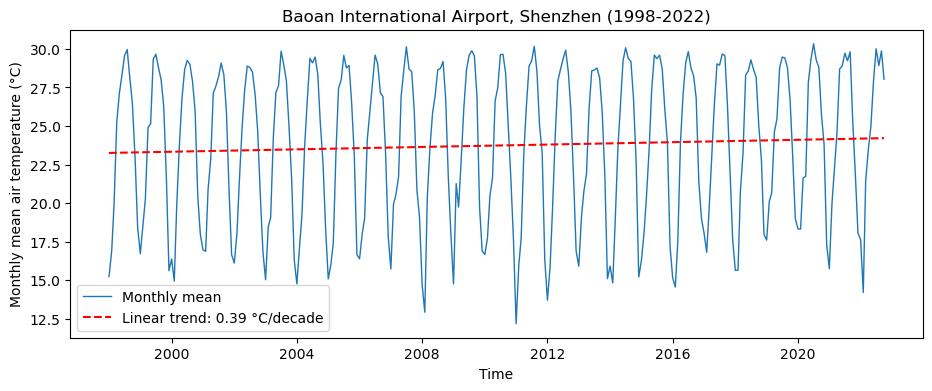

Trend = 0.0387 °C/yr, r = 0.056, p = 0.339


In [11]:
# Time index
time_col = "DATE" if "DATE" in sz.columns else sz.columns[0]
sz["time"] = pd.to_datetime(sz[time_col])
sz = sz.set_index("time").sort_index()

# Monthly mean and plot
monthly = sz["T"].resample("MS").mean()

m = monthly.dropna()
x = (m.index - m.index[0]).days / 365.25      # time in years
res = stats.linregress(x, m.values)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly.values, lw=1, label="Monthly mean")
ax.plot(m.index, res.intercept + res.slope * x, "r--",
        label=f"Linear trend: {res.slope*10:.2f} °C/decade")
ax.set_xlabel("Time")
ax.set_ylabel("Monthly mean air temperature (°C)")
ax.set_title("Baoan International Airport, Shenzhen (1998-2022)")
ax.legend()
plt.show()

print(f"Trend = {res.slope:.4f} °C/yr, r = {res.rvalue:.3f}, p = {res.pvalue:.3g}")

In [12]:
# Optional: remove the seasonal cycle for a cleaner trend
clim = monthly.groupby(monthly.index.month).transform("mean")
anom = (monthly - clim).dropna()
xa = (anom.index - anom.index[0]).days / 365.25
res_a = stats.linregress(xa, anom.values)
print(f"Deseasonalised trend = {res_a.slope*10:.3f} °C/decade, p = {res_a.pvalue:.3g}")

Deseasonalised trend = 0.230 °C/decade, p = 0.0074


In [13]:
# Q3
IB_FILE = r"E:\ibtracs.ALL.list.v04r00\ibtracs.ALL.list.v04r00.csv"
# skiprows=[1, 2] skips the units row(s) under the header, so numeric columns parse as numbers.
# na_values turns placeholder names into NaN.
df = pd.read_csv(IB_FILE,
                 usecols=range(17),
                 skiprows=[1, 2],
                 parse_dates=["ISO_TIME"],
                 na_values=["NOT_NAMED", "NAME", " "])

# Make sure the numeric columns are numeric
for c in ["WMO_WIND", "LAT", "LON"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print(df.shape)
print(df.head())

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_40592\3444993216.py:4: DtypeWarning: Columns (5,12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(IB_FILE,


(707176, 17)
             SID  SEASON  NUMBER BASIN SUBBASIN NAME            ISO_TIME  \
0  1842298N11080    1842       1    NI       BB  NaN 1842-10-25 06:00:00   
1  1842298N11080    1842       1    NI       BB  NaN 1842-10-25 09:00:00   
2  1842298N11080    1842       1    NI       BB  NaN 1842-10-25 12:00:00   
3  1842298N11080    1842       1    NI       BB  NaN 1842-10-25 15:00:00   
4  1842298N11080    1842       1    NI       AS  NaN 1842-10-25 18:00:00   

  NATURE      LAT      LON  WMO_WIND  WMO_PRES WMO_AGENCY TRACK_TYPE  \
0     NR  10.8709  79.8265       NaN       NaN        NaN       main   
1     NR  10.8431  79.3524       NaN       NaN        NaN       main   
2     NR  10.8188  78.8772       NaN       NaN        NaN       main   
3     NR  10.8000  78.4000       NaN       NaN        NaN       main   
4     NR  10.7884  77.9194       NaN       NaN        NaN       main   

   DIST2LAND  LANDFALL           IFLAG  
0          0       0.0  __________P___  
1          0   

In [14]:
# 3.1 Names of the 10 largest hurricanes by wind speed
storm = df.groupby("SID").agg(NAME=("NAME", "first"),
                              SEASON=("SEASON", "first"),
                              MAX_WIND=("WMO_WIND", "max"))
top10 = storm.sort_values("MAX_WIND", ascending=False).head(10)
print(top10)
print("\nNames:", top10["NAME"].tolist())

                   NAME  SEASON  MAX_WIND
SID                                      
2015293N13266  PATRICIA    2015     185.0
1980214N11330     ALLEN    1980     165.0
2019236N10314    DORIAN    2019     160.0
1988253N12306   GILBERT    1988     160.0
2005289N18282     WILMA    2005     160.0
1935241N23291      None    1935     160.0
1997253N12255     LINDA    1997     160.0
2017242N16333      IRMA    2017     155.0
1998295N12284     MITCH    1998     155.0
2009288N07267      RICK    2009     155.0

Names: ['PATRICIA', 'ALLEN', 'DORIAN', 'GILBERT', 'WILMA', None, 'LINDA', 'IRMA', 'MITCH', 'RICK']


In [15]:
# 3.2 Wind speed of the 20 strongest-wind hurricanes
top20 = storm.sort_values("MAX_WIND", ascending=False).head(20)
print(top20["MAX_WIND"])

SID
2015293N13266    185.0
1980214N11330    165.0
2019236N10314    160.0
1988253N12306    160.0
2005289N18282    160.0
1935241N23291    160.0
1997253N12255    160.0
2017242N16333    155.0
1998295N12284    155.0
2009288N07267    155.0
2005261N21290    155.0
1955265N13307    150.0
1992230N11325    150.0
2016041S14170    150.0
1977242N27272    150.0
2017260N12310    150.0
2005236N23285    150.0
1959249N19181    150.0
1979238N12324    150.0
1994222N11267    150.0
Name: MAX_WIND, dtype: float64


In [16]:
# 3.3 Datapoints per basin
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
print(basin_counts)

BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
dtype: int64


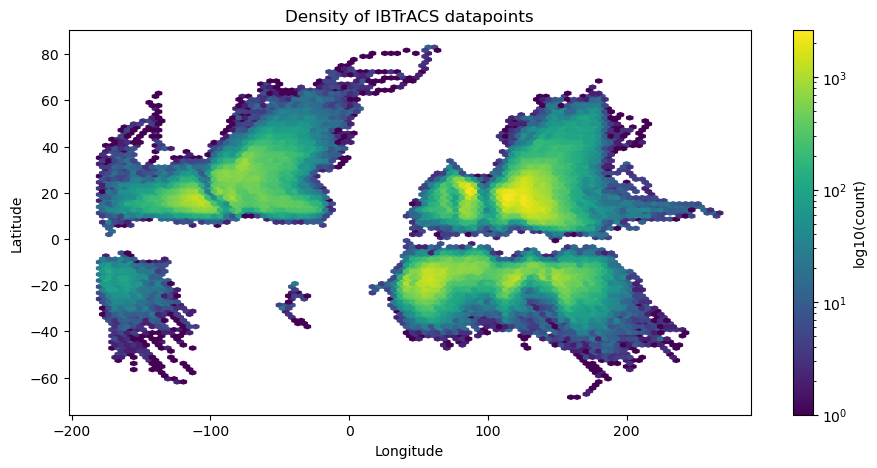

In [17]:
# 3.4 Hexbin plot of datapoint locations
fig, ax = plt.subplots(figsize=(11, 5))
hb = ax.hexbin(df["LON"], df["LAT"], gridsize=100, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, label="log10(count)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Density of IBTrACS datapoints")
plt.show()

Mangkhut datapoints: 99


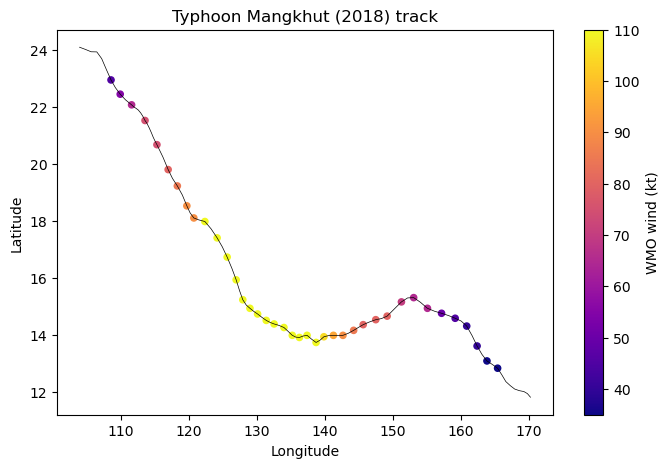

In [18]:
# 3.5 Track of Typhoon Mangkhut (2018)
mk = df[(df["NAME"] == "MANGKHUT") & (df["ISO_TIME"].dt.year == 2018)]
print("Mangkhut datapoints:", len(mk))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mk["LON"], mk["LAT"], "k-", lw=0.5)
sc = ax.scatter(mk["LON"], mk["LAT"], c=mk["WMO_WIND"], cmap="plasma", s=20)
fig.colorbar(sc, label="WMO wind (kt)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Typhoon Mangkhut (2018) track")
plt.show()

In [19]:
# 3.6 Filter: since 1970, Western (WP) and Eastern (EP) North Pacific
dfw = df[(df["ISO_TIME"].dt.year >= 1970) & (df["BASIN"].isin(["WP", "EP"]))].copy()
print("Filtered datapoints:", len(dfw))

Filtered datapoints: 176352


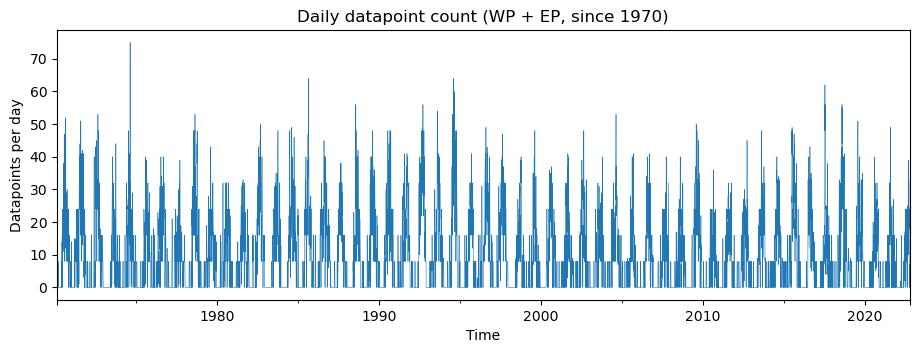

In [20]:
# 3.7 Number of datapoints per day
daily = dfw.set_index("ISO_TIME").resample("D").size()

fig, ax = plt.subplots(figsize=(11, 3.5))
daily.plot(ax=ax, lw=0.4)
ax.set_xlabel("Time")
ax.set_ylabel("Datapoints per day")
ax.set_title("Daily datapoint count (WP + EP, since 1970)")
plt.show()

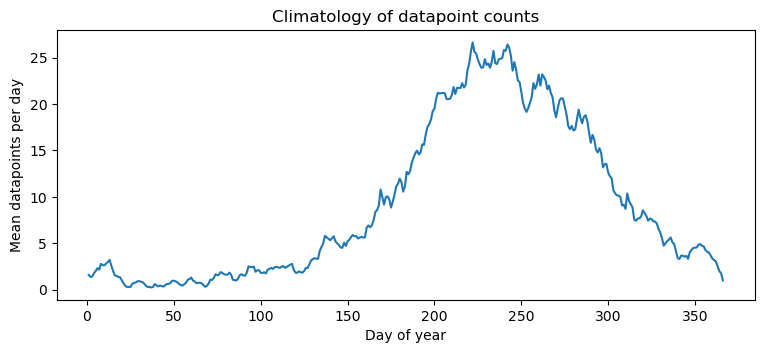

In [21]:
# 3.8 Climatology as a function of day of year
clim = daily.groupby(daily.index.dayofyear).mean()

fig, ax = plt.subplots(figsize=(9, 3.5))
clim.plot(ax=ax)
ax.set_xlabel("Day of year")
ax.set_ylabel("Mean datapoints per day")
ax.set_title("Climatology of datapoint counts")
plt.show()

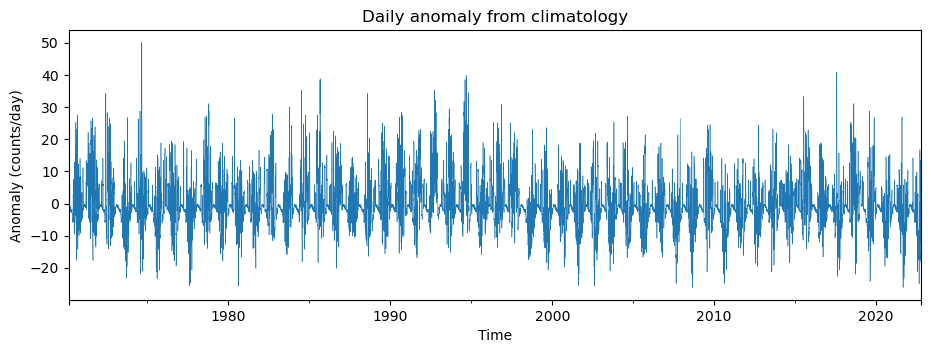

In [22]:
# 3.9 Anomaly of daily counts from the climatology
anom = daily - daily.index.dayofyear.map(clim).values

fig, ax = plt.subplots(figsize=(11, 3.5))
anom.plot(ax=ax, lw=0.4)
ax.set_xlabel("Time")
ax.set_ylabel("Anomaly (counts/day)")
ax.set_title("Daily anomaly from climatology")
plt.show()

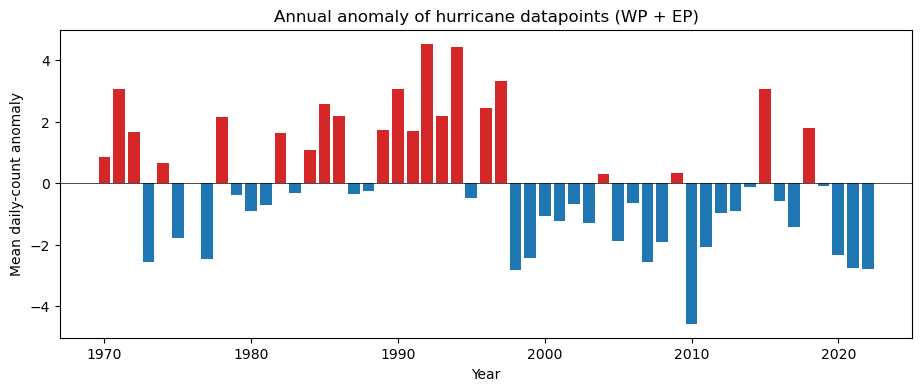

Years with |anomaly| > 1 std:
ISO_TIME
1971-01-01    3.07
1973-01-01   -2.56
1977-01-01   -2.46
1978-01-01    2.14
1985-01-01    2.57
1986-01-01    2.18
1990-01-01    3.07
1992-01-01    4.54
1993-01-01    2.19
1994-01-01    4.42
1996-01-01    2.43
1997-01-01    3.33
1998-01-01   -2.83
1999-01-01   -2.43
2007-01-01   -2.56
2010-01-01   -4.57
2015-01-01    3.07
2020-01-01   -2.34
2021-01-01   -2.75
2022-01-01   -2.79


In [23]:
# 3.10 Resample anomaly to annual resolution
anom_y = anom.resample("YS").mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(anom_y.index.year, anom_y.values,
       color=np.where(anom_y.values > 0, "tab:red", "tab:blue"))
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Year")
ax.set_ylabel("Mean daily-count anomaly")
ax.set_title("Annual anomaly of hurricane datapoints (WP + EP)")
plt.show()

thr = anom_y.std()
print("Years with |anomaly| > 1 std:")
print(anom_y[anom_y.abs() > thr].round(2).to_string())

In [24]:
# Q4
# 4.1 Clean 
FILE = r"C:\Users\Lenovo\Desktop\4.xlsx"   

raw = pd.read_excel(FILE, header=None)     # the sheet has 4 header rows (names, sub-names, units, limits)
data = raw.iloc[4:].copy()                 # real data start at row 5

# pick columns by position and give them English names
cols = {0: "well", 1: "date", 10: "well_depth_m", 11: "depth_to_water_m", 12: "water_level_m",
        13: "water_temp_C", 16: "pH", 17: "ORP_mV", 18: "TDS_mgL", 20: "EC_uScm", 22: "DO_pct"}
df = data[list(cols)].rename(columns=cols)

# the well ID is only written on the first row of each well -> fill down
df["well"] = df["well"].ffill().astype(str)

# dates look like "2025.7.7"
df["date"] = pd.to_datetime(df["date"].astype(str).str.strip(), format="%Y.%m.%d", errors="coerce")

# text such as "14.57mS/cm" or "/" becomes NaN
for c in df.columns.drop(["well", "date"]):
    df[c] = pd.to_numeric(df[c], errors="coerce")

n0 = len(df)
df = df.dropna(subset=["date", "water_level_m"])                 # missing values
df = df[df["water_level_m"].between(300, 600)]                   # physically implausible values
df["pH"] = df["pH"].where(df["pH"].between(0, 14))               # bad pH -> NaN
df = df.sort_values(["well", "date"]).reset_index(drop=True)
print(f"Kept {len(df)} of {n0} rows after cleaning")
print(df.isna().sum())

# wells with at least 6 visits are used for time series and statistics
counts = df.groupby("well").size()
main = counts[counts >= 6].index
sub = df[df["well"].isin(main)].copy()
print("Wells used:", list(main))

Kept 128 of 141 rows after cleaning
well                 0
date                 0
well_depth_m        18
depth_to_water_m     3
water_level_m        0
water_temp_C        49
pH                  49
ORP_mV              49
TDS_mgL             49
EC_uScm             49
DO_pct              75
dtype: int64
Wells used: ['306Q', '307', '308', 'WR05T', 'WR39', 'X13', 'X13Q', 'Y0', 'Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6']


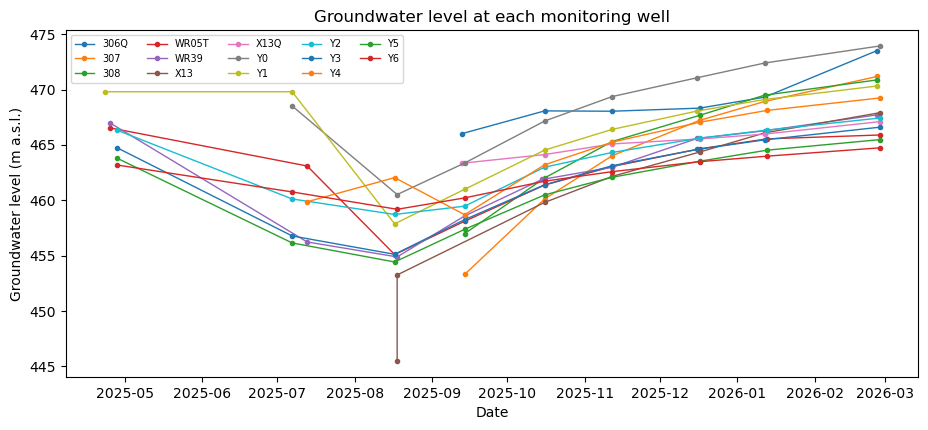

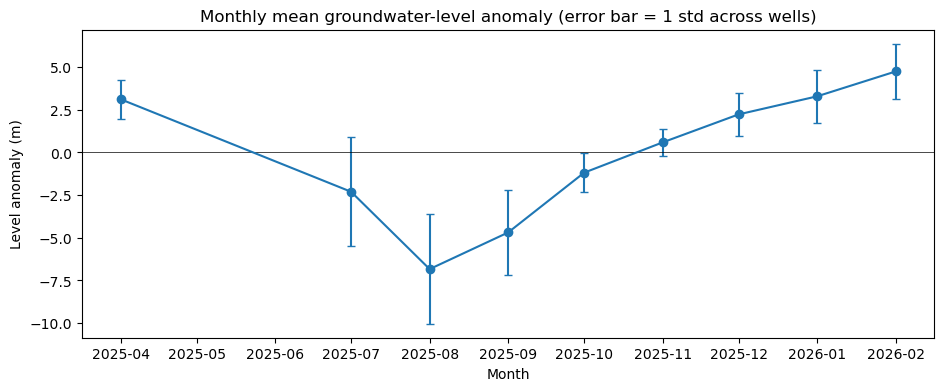

In [25]:
# 4.2 Time series
fig, ax = plt.subplots(figsize=(11, 4.5))
for w in main:
    s = sub[sub["well"] == w]
    ax.plot(s["date"], s["water_level_m"], marker="o", ms=3, lw=1, label=w)
ax.set_xlabel("Date"); ax.set_ylabel("Groundwater level (m a.s.l.)")
ax.set_title("Groundwater level at each monitoring well")
ax.legend(ncol=5, fontsize=7)
plt.show()

# anomaly relative to each well's own mean, averaged by month
sub["anom"] = sub["water_level_m"] - sub.groupby("well")["water_level_m"].transform("mean")
sub["month"] = sub["date"].dt.to_period("M").dt.to_timestamp()
mm = sub.groupby("month")["anom"].agg(["mean", "std", "count"])

fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(mm.index, mm["mean"], yerr=mm["std"], fmt="o-", capsize=3)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("Month"); ax.set_ylabel("Level anomaly (m)")
ax.set_title("Monthly mean groundwater-level anomaly (error bar = 1 std across wells)")
plt.show()

In [26]:

# 4.3 Statistical checks
# 1) descriptive statistics
print("1) Descriptive statistics of water level (m)")
print(sub["water_level_m"].describe().round(2), "\n")

1) Descriptive statistics of water level (m)
count    110.00
mean     463.79
std        4.82
min      445.48
25%      460.81
50%      464.44
75%      467.08
max      473.93
Name: water_level_m, dtype: float64 



In [27]:
# 2) linear trend of each well, then test whether the mean slope differs from 0
rows = []
for w in main:
    s = sub[sub["well"] == w]
    t = (s["date"] - s["date"].min()).dt.days.values
    r = stats.linregress(t, s["water_level_m"])
    rows.append((w, len(s), r.slope * 30, r.pvalue))
tr = pd.DataFrame(rows, columns=["well", "n", "slope_m_per_month", "p_value"])
print("2) Per-well trend"); print(tr.round(4))
tt = stats.ttest_1samp(tr["slope_m_per_month"], 0)
print(f"   Mean slope = {tr['slope_m_per_month'].mean():.2f} m/month, t-test p = {tt.pvalue:.4f}\n")

2) Per-well trend
     well  n  slope_m_per_month  p_value
0    306Q  6             1.1339   0.0117
1     307  6             3.1328   0.0026
2     308  6             2.4764   0.0023
3   WR05T  9             0.2845   0.5376
4    WR39  9             0.6564   0.2399
5     X13  7             3.0115   0.0032
6    X13Q  6             0.6540   0.0001
7      Y0  8             1.3288   0.0262
8      Y1  9             0.2385   0.6510
9      Y2  9             0.4869   0.1986
10     Y3  9             0.6857   0.1418
11     Y4  8             1.3862   0.0009
12     Y5  9             0.6529   0.1473
13     Y6  9             0.3270   0.1140
   Mean slope = 1.18 m/month, t-test p = 0.0007



In [28]:
# 3) seasonal contrast: Jul-Sep (low) vs Dec-Feb (high), Mann-Whitney U test
low = sub[sub["date"].dt.month.isin([7, 8, 9])]["anom"]
high = sub[sub["date"].dt.month.isin([12, 1, 2])]["anom"]
u = stats.mannwhitneyu(low, high)
print(f"3) Mean anomaly Jul-Sep = {low.mean():.2f} m, Dec-Feb = {high.mean():.2f} m, p = {u.pvalue:.2e}\n")

3) Mean anomaly Jul-Sep = -4.76 m, Dec-Feb = 3.42 m, p = 1.13e-12



In [29]:
# 4) Spearman correlation of water level with water temperature
v = sub[["water_level_m", "water_temp_C"]].dropna()
sp = stats.spearmanr(v["water_level_m"], v["water_temp_C"])
print(f"4) Spearman(level, temperature) = {sp.statistic:.2f}, p = {sp.pvalue:.2e}, n = {len(v)}\n")

4) Spearman(level, temperature) = -0.61, p = 9.33e-09, n = 74



In [30]:
# 5) normality of the anomalies (Shapiro-Wilk)
sw = stats.shapiro(sub["anom"])
print(f"5) Shapiro-Wilk: W = {sw.statistic:.3f}, p = {sw.pvalue:.4f} ->",
      "normal" if sw.pvalue > 0.05 else "not normal", "\n")

5) Shapiro-Wilk: W = 0.958, p = 0.0017 -> not normal 



In [31]:
# 6) outliers (|z| > 3)
z = (sub["anom"] - sub["anom"].mean()) / sub["anom"].std()
print("6) Number of |z|>3 outliers:", int((z.abs() > 3).sum()), "\n")

6) Number of |z|>3 outliers: 1 



In [32]:
# 7) difference between wells (Kruskal-Wallis)
kw = stats.kruskal(*[g["water_level_m"].values for _, g in sub.groupby("well")])
print(f"7) Kruskal-Wallis across wells: H = {kw.statistic:.1f}, p = {kw.pvalue:.4f}")

7) Kruskal-Wallis across wells: H = 31.6, p = 0.0028
